# TP - Prediction des réadmissions des patients diabetiques

## 0- Bibliothèques

In [1]:
%pip -q install catboost

In [2]:
import zipfile
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from catboost import CatBoostClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (f1_score, accuracy_score, recall_score, precision_score,
                             average_precision_score, classification_report,
                             ConfusionMatrixDisplay)


## 1- DATA : Chargement des données

In [4]:
# on charge les donné du fichier zip
with zipfile.ZipFile('/content/diabetic_data.csv.zip') as z:
    df = pd.read_csv(z.open('diabetic_data.csv'), na_values=['?', 'Unknown/Invalid'], low_memory=False)

print('Dimensions :', df.shape)
display(df.head())
df.info()

Dimensions : (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      99493 non-null   object
 3   gender                    101763 non-null  object
 4   age                       101766 non-null  object
 5   weight                    3197 non-null    object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                61510 non-null   object
 11  medical_specialty         51817 non-null   object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

## 2- EDA : Exploration des données

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64


,0
weight,98569
max_glu_serum,96420
A1Cresult,84748
medical_specialty,49949
payer_code,40256
race,2273
diag_3,1423
diag_2,358
diag_1,21
gender,3


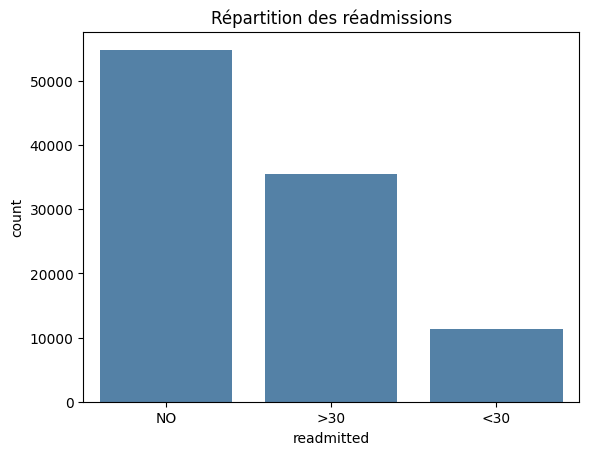

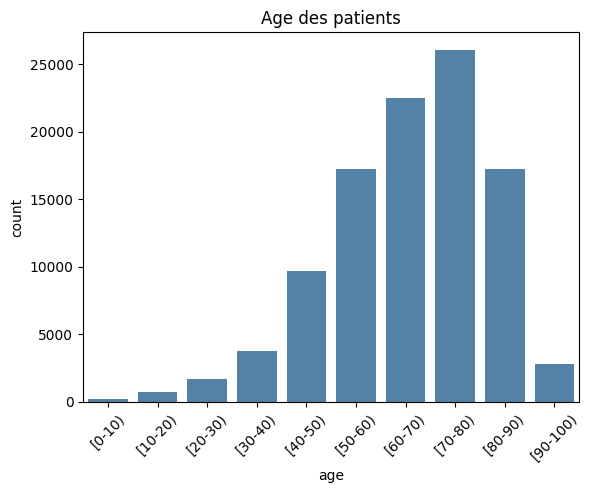

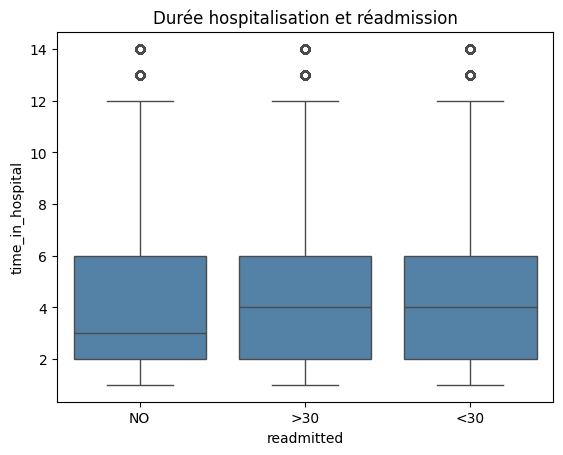

In [5]:
# on regarde les valeurs manquante
print(df['readmitted'].value_counts())
display(df.isna().sum().sort_values(ascending=False).head(10))

sns.countplot(data=df, x='readmitted', order=['NO', '>30', '<30'], color='steelblue')
plt.title('Répartition des réadmissions')
plt.show()

sns.countplot(data=df, x='age', order=sorted(df['age'].dropna().unique()), color='steelblue')
plt.xticks(rotation=45)
plt.title('Age des patients')
plt.show()

sns.boxplot(data=df, x='readmitted', y='time_in_hospital', color='steelblue')
plt.title('Durée hospitalisation et réadmission')
plt.show()

## 3- PRÉTRAITEMENT : Choix des variables

In [6]:
# 1 = réadmis avant 30 jours
df['target'] = (df['readmitted'] == '<30').astype(int)

cols = ['age', 'gender', 'race', 'time_in_hospital', 'num_lab_procedures',
        'num_procedures', 'num_medications', 'number_outpatient',
        'number_emergency', 'number_inpatient', 'number_diagnoses',
        'A1Cresult', 'max_glu_serum', 'change', 'diabetesMed', 'insulin',
        'admission_type_id', 'admission_source_id', 'diag_1', 'diag_2', 'diag_3']

X = df[cols].copy()
y = df['target']

for c in ['admission_type_id', 'admission_source_id', 'diag_1', 'diag_2', 'diag_3']:
    X[c] = X[c].astype('string')

cat = X.select_dtypes(include=['object', 'string']).columns.tolist()
num = [c for c in cols if c not in cat]
X[cat] = X[cat].fillna('Unknown').astype(str)

print('Cible :')
print(y.value_counts())

Cible :
target
0    90409
1    11357
Name: count, dtype: int64


## 4- TRANSFORMATION : Train, validation, test

In [7]:
# on garde chaque patient dans un seul groupe
split = GroupShuffleSplit(test_size=0.2, random_state=42)
a, b = next(split.split(X, y, groups=df['patient_nbr']))
X_train, X_test = X.iloc[a], X.iloc[b]
y_train, y_test = y.iloc[a], y.iloc[b]

split2 = GroupShuffleSplit(test_size=0.25, random_state=42)
i, j = next(split2.split(X_train, y_train, groups=df['patient_nbr'].iloc[a]))
X_fit, X_val = X_train.iloc[i], X_train.iloc[j]
y_fit, y_val = y_train.iloc[i], y_train.iloc[j]

preprocess = ColumnTransformer([
    ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), num),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat)
])

print('Train :', X_fit.shape, 'Validation :', X_val.shape, 'Test :', X_test.shape)

Train : (60988, 21) Validation : (20625, 21) Test : (20153, 21)


## 5- MACHINE LEARNING : Deux modèles

In [8]:
# premier modele : regression logistique
lr = make_pipeline(preprocess, LogisticRegression(max_iter=1200, class_weight='balanced'))
lr.fit(X_fit, y_fit)

# deuxieme modele : CatBoost
cb = CatBoostClassifier(iterations=350, depth=6, learning_rate=0.06,
                        random_seed=42, verbose=False)
cb.fit(X_fit, y_fit, cat_features=cat,
       eval_set=(X_val, y_val), early_stopping_rounds=35)

modeles = {'Logistic Regression': lr, 'CatBoost': cb}
print('Entrainement terminé')

Entrainement terminé


## 6- ÉVALUATION : Comparaison et résultats

,Modèle,AP validation,F1 validation,Seuil
1,CatBoost,0.211224,0.264245,0.125
0,Logistic Regression,0.195041,0.254001,0.550


Meilleur modèle : CatBoost | Seuil : 0.125
Accuracy : 0.72
Precision : 0.177
Recall : 0.445
F1-score : 0.254
Average Precision : 0.192
              precision    recall  f1-score   support

           0       0.92      0.75      0.83     18002
           1       0.18      0.44      0.25      2151

    accuracy                           0.72     20153
   macro avg       0.55      0.60      0.54     20153
weighted avg       0.84      0.72      0.77     20153



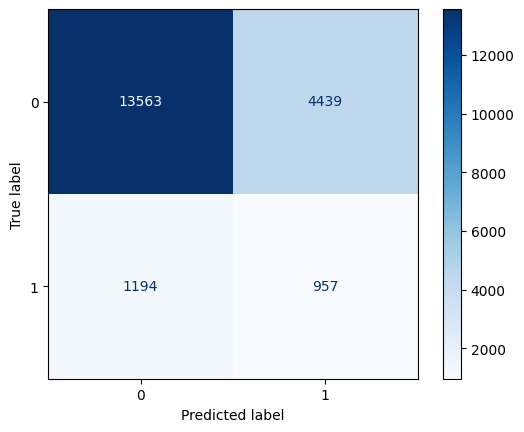

In [9]:
# on choisi le seuil avec la validation
seuils = np.arange(0.10, 0.61, 0.025)
lignes = []
for nom, modele in modeles.items():
    p = modele.predict_proba(X_val)[:, 1]
    f1 = [f1_score(y_val, p >= s) for s in seuils]
    k = np.argmax(f1)
    lignes.append([nom, average_precision_score(y_val, p), f1[k], seuils[k]])

resultats = pd.DataFrame(lignes, columns=['Modèle', 'AP validation', 'F1 validation', 'Seuil'])
display(resultats.sort_values('AP validation', ascending=False))

best_row = resultats.sort_values('AP validation', ascending=False).iloc[0]
nom = best_row['Modèle']
seuil = float(best_row['Seuil'])
meilleur = modeles[nom]

proba = meilleur.predict_proba(X_test)[:, 1]
pred = (proba >= seuil).astype(int)

print('Meilleur modèle :', nom, '| Seuil :', round(seuil, 3))
print('Accuracy :', round(accuracy_score(y_test, pred), 3))
print('Precision :', round(precision_score(y_test, pred, zero_division=0), 3))
print('Recall :', round(recall_score(y_test, pred), 3))
print('F1-score :', round(f1_score(y_test, pred), 3))
print('Average Precision :', round(average_precision_score(y_test, proba), 3))
print(classification_report(y_test, pred, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, pred, cmap='Blues')
plt.show()

## 7- SAUVEGARDE : Garder le meilleur modèle

In [10]:
# on garde aussi les colonnes et le seuil
joblib.dump({'modele': meilleur, 'colonnes': cols, 'categories': cat,
             'seuil': seuil}, 'model.joblib')

['model.joblib']

## 8- DÉPLOIEMENT : API et Docker



In [11]:
%%writefile app.py
import joblib
import pandas as pd
from fastapi import FastAPI

objet = joblib.load('model.joblib')
app = FastAPI()

@app.post('/predict')
def predict(patient: dict):
    x = pd.DataFrame([patient]).reindex(columns=objet['colonnes'])
    x[objet['categories']] = x[objet['categories']].fillna('Unknown').astype(str)
    p = float(objet['modele'].predict_proba(x)[0, 1])
    return {'prediction': int(p >= objet['seuil']), 'probabilite': round(p, 3)}

Writing app.py


In [12]:
%%writefile requirements.txt
pandas
scikit-learn
catboost
joblib
fastapi
uvicorn

Writing requirements.txt


In [13]:
%%writefile Dockerfile
FROM python:3.11-slim
WORKDIR /app
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY app.py model.joblib ./
EXPOSE 8000
CMD ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"]

Writing Dockerfile


In [14]:
# on télécharge les fichiers pour Docker
from google.colab import files

with zipfile.ZipFile('diabetes_docker.zip', 'w') as z:
    for fichier in ['app.py', 'requirements.txt', 'Dockerfile', 'model.joblib']:
        z.write(fichier)

files.download('diabetes_docker.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Commandes à lancer sur ton ordinateur (avec Docker installé)**

```bash
docker build -t diabetes-readmission .
docker run --rm -p 8000:8000 diabetes-readmission
```

Ouvrir `http://localhost:8000/docs` pour tester l’API. Résultats exploratoires, pas un outil de décision médicale.